# Application 3A — margins, hinge loss, and a linear SVM

**Question:** What does an SVM optimize, and which rows determine its boundary?

For input x, slopes w, and intercept b, $f(x)=w^Tx+b$. Labels are $y\in\{-1,+1\}$;
predict +1 at $f(x)\ge0$, otherwise −1. The **functional margin** is yf(x), and **hinge loss**
is $\max(0,1-yf(x))$. Scores are not probabilities. A **support vector** has a nonzero dual coefficient.

Verify an exact solution, check a subgradient, select C, and inspect a conflicting row.
Use 60/20/20 splits; five-fold training cross-validation (CV) selects C by **balanced accuracy**
(the average class recall). Validation only audits; test comes last.

`SVC` is the classifier: `fit` learns, `decision_function` returns scores, and `predict` returns labels
with the library's tie rule. Here we threshold explicitly. Larger C penalizes margin violations more.
No download needed. See [lecture](03_support_vector_machines.pdf) and [solution](Solutions/03_A_margins_and_hinge_solution.pdf).

## 1. Verify a maximum-margin solution

For the five supplied rows, $w=(1,0),b=0$: boundary $x_1=0$, supporting lines $x_1=\pm1$,
one-sided geometric margin $1/\|w\|=1$. The negative row (−1,0) requires $w_1-b\ge1$;
averaging constraints at $(1,\pm1)$ gives $w_1+b\ge1$. Thus $w_1\ge1$: no feasible w has smaller norm.

Dual coefficients $\alpha=(0,1/2,1/4,1/4,0)$ certify the optimum:
$w=\sum_i\alpha_i y_i x_i$, $\sum_i\alpha_i y_i=0$, and primal/dual objectives both equal 1/2.
`SVC(kernel="linear",C=10)` recovers this solution here; large C does not generally prove feasibility.
`coef_`/`intercept_` store parameters; `support_` stores training-row positions.
`assert_allclose` checks agreement; `contour` draws levels −1,0,+1.

,x1,x2,label,functional margin,dual alpha
0,-3.0,1.0,-1,3.0,0.00
1,-1.0,0.0,-1,1.0,0.50
2,1.0,-1.0,1,1.0,0.25
3,1.0,1.0,1,1.0,0.25
4,3.0,0.0,1,3.0,0.00


Primal and dual objectives: 0.5 0.5
Support row positions: [1 2 3]


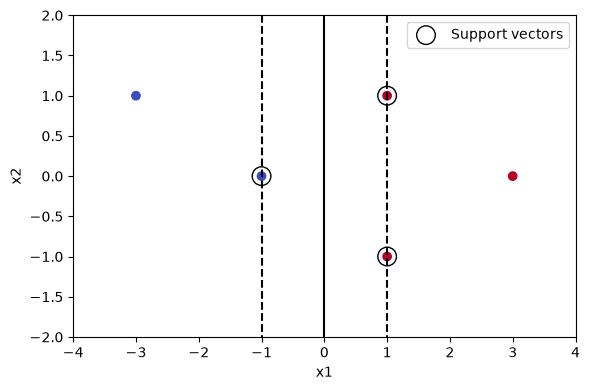

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, roc_auc_score

X_small = np.array([[-3, 1], [-1, 0], [1, -1], [1, 1], [3, 0]], dtype=float)
y_small = np.array([-1, -1, 1, 1, 1])
w_exact = np.array([1.0, 0.0])
b_exact = 0.0
alpha = np.array([0.0, 0.5, 0.25, 0.25, 0.0])
margin = y_small * (X_small @ w_exact + b_exact)
primal = np.dot(w_exact, w_exact) / 2
dual = alpha.sum() - np.linalg.norm((alpha * y_small) @ X_small) ** 2 / 2
assert np.all(margin >= 1) and np.all((alpha >= 0) & (alpha <= 10))
np.testing.assert_allclose(alpha @ y_small, 0)
np.testing.assert_allclose((alpha * y_small) @ X_small, w_exact)
np.testing.assert_allclose(alpha * (margin - 1), 0)
np.testing.assert_allclose(primal, dual)
small_model = SVC(kernel="linear", C=10, tol=1e-10).fit(X_small, y_small)
np.testing.assert_allclose(small_model.coef_[0], w_exact, atol=1e-6)
np.testing.assert_allclose(small_model.intercept_[0], b_exact, atol=1e-6)
display(pd.DataFrame({"x1": X_small[:, 0], "x2": X_small[:, 1],
                      "label": y_small, "functional margin": margin, "dual alpha": alpha}))
print("Primal and dual objectives:", primal, dual)
print("Support row positions:", small_model.support_)
xx, yy = np.meshgrid(np.linspace(-4, 4, 150), np.linspace(-2, 2, 100))
plt.figure(figsize=(6, 4))
plt.scatter(X_small[:, 0], X_small[:, 1], c=y_small, cmap="coolwarm", vmin=-1, vmax=1)
plt.scatter(X_small[small_model.support_, 0], X_small[small_model.support_, 1],
            s=180, facecolors="none", edgecolors="black", label="Support vectors")
plt.contour(xx, yy, xx, levels=[-1, 0, 1], colors="black", linestyles=["--", "-", "--"])
plt.xlabel("x1"); plt.ylabel("x2"); plt.legend(); plt.tight_layout(); plt.show()

## 2. Generate overlapping classes

Draw 400 equally likely labels and independent $x_1\mid y\sim N(1.5y,0.8^2)$, $x_2\sim N(0,1)$.
`train_test_split(...,stratify=y)` preserves approximate class proportions; seed 23 fixes splits.
`StandardScaler.fit` learns training means/scales; `transform` reuses them.
This scaler serves derivative/perturbation checks; CV fits a fresh scaler within each fold.

In [2]:
rng = np.random.default_rng(17)
y = rng.choice([-1, 1], size=400)
X = np.column_stack([1.5 * y + rng.normal(0, 0.8, 400), rng.normal(0, 1, 400)])
train_valid_ids, test_ids = train_test_split(np.arange(len(y)), test_size=0.2, random_state=23, stratify=y)
train_ids, valid_ids = train_test_split(train_valid_ids, test_size=0.25, random_state=23,
                                      stratify=y[train_valid_ids])
assert set(train_ids).isdisjoint(valid_ids) and set(train_ids).isdisjoint(test_ids)
assert set(valid_ids).isdisjoint(test_ids)
X_train, y_train = X[train_ids], y[train_ids]
X_valid, y_valid = X[valid_ids], y[valid_ids]
X_test, y_test = X[test_ids], y[test_ids]
scaler = StandardScaler().fit(X_train)
Z_train = scaler.transform(X_train)
print("Train / validation / test rows:", len(train_ids), len(valid_ids), len(test_ids))
print("Training class counts:", dict(zip(*np.unique(y_train, return_counts=True))))

Train / validation / test rows: 240 80 80
Training class counts: {np.int64(-1): np.int64(122), np.int64(1): np.int64(118)}


## 3. Check the hinge subgradient

For standardized inputs $z_i$ and $\beta=(b,w_1,w_2)$,
$$J(\beta)=\frac1n\sum_i\max(0,1-y_i(w^Tz_i+b))+\frac\lambda2\|w\|^2.$$
Active rows have $y_if_i<1$:
$g_b=-\sum_{active}y_i/n$, $g_w=\lambda w-\sum_{active}y_i z_i/n$.
The intercept is unpenalized; at margin 1 choose zero loss subgradient.

`hinge_objective` returns J and this subgradient; `maximum` applies the hinge and a mask selects active rows.
Check central differences **away from hinges**, where ordinary derivatives exist.
This verifies the formula; `SVC`, not a custom optimizer, fits the later models.

In [3]:
def hinge_objective(beta, inputs, labels, penalty):
    scores = beta[0] + inputs @ beta[1:]
    margins = labels * scores
    active = margins < 1
    loss = np.maximum(0, 1 - margins).mean() + penalty * np.dot(beta[1:], beta[1:]) / 2
    gradient = np.empty_like(beta)
    gradient[0] = -labels[active].sum() / len(labels)
    gradient[1:] = penalty * beta[1:] - inputs[active].T @ labels[active] / len(labels)
    return loss, gradient

beta_check = np.array([0.2, 0.6, -0.1])
penalty = 0.1
h = 1e-6
check_margins = y_train * (beta_check[0] + Z_train @ beta_check[1:])
assert np.min(np.abs(check_margins - 1)) > 1e-4
loss, analytic = hinge_objective(beta_check, Z_train, y_train, penalty)
numerical = np.zeros(3)
for j in range(3):
    plus, minus = beta_check.copy(), beta_check.copy()
    plus[j] += h
    minus[j] -= h
    numerical[j] = (hinge_objective(plus, Z_train, y_train, penalty)[0]
                    - hinge_objective(minus, Z_train, y_train, penalty)[0]) / (2 * h)
np.testing.assert_allclose(analytic, numerical, atol=1e-7)
display(pd.DataFrame({"analytic": analytic, "finite difference": numerical}, index=["b", "w1", "w2"]))

,analytic,finite difference
b,0.116667,0.116667
w1,-0.672343,-0.672343
w2,-0.047437,-0.047437


## 4. Select C by training CV

`SVC` minimizes $\|w\|^2/2+C\sum_i\max(0,1-y_if_i)$: divide by nC to obtain $\lambda=1/(nC)$.
Hold C fixed across folds. `make_pipeline(StandardScaler(),SVC(...))` refits scaling inside each fit;
`StratifiedKFold` and `cross_val_score` use five folds of 192 fitting/48 scoring rows.
Maximize mean balanced accuracy (equal weight per class), break ties by listed C order, then refit
on all training rows. Fold SD describes variation, not a confidence interval.

In [4]:
C_values = [0.01, 0.1, 1, 10, 100]
folds = list(StratifiedKFold(5, shuffle=True, random_state=23).split(X_train, y_train))
cv_rows = []
for C in C_values:
    model = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C, tol=1e-6))
    scores = cross_val_score(model, X_train, y_train, cv=folds, scoring="balanced_accuracy")
    cv_rows.append({"C": C, "CV balanced accuracy": scores.mean(), "fold SD": scores.std(ddof=1)})
cv_results = pd.DataFrame(cv_rows)
best_C = float(cv_results.loc[cv_results["CV balanced accuracy"].idxmax(), "C"])
selected = make_pipeline(StandardScaler(), SVC(kernel="linear", C=best_C, tol=1e-6))
selected.fit(X_train, y_train)
assert selected.named_steps["svc"].fit_status_ == 0
display(cv_results)
print("Frozen C:", best_C)

,C,CV balanced accuracy,fold SD
0,0.01,0.970819,0.011414
1,0.10,0.962486,0.027159
2,1.00,0.971167,0.018825
3,10.00,0.958486,0.025688
4,100.00,0.962833,0.027422


Frozen C: 1.0


## 5. Add a conflicting row as a diagnostic

Add (2.5,0) with label −1 and compare C=0.01 versus 100 before/after addition.
Keep the original scaler fixed; do not change `selected`, its CV choices, or held-out rows.
`maximum(0,1-y*f)` computes slack: a correct classification may still have positive slack.
Inspect zero-score boundaries, support counts, mean slack, and validation **score** changes.
Larger C need not move every dataset's boundary more.

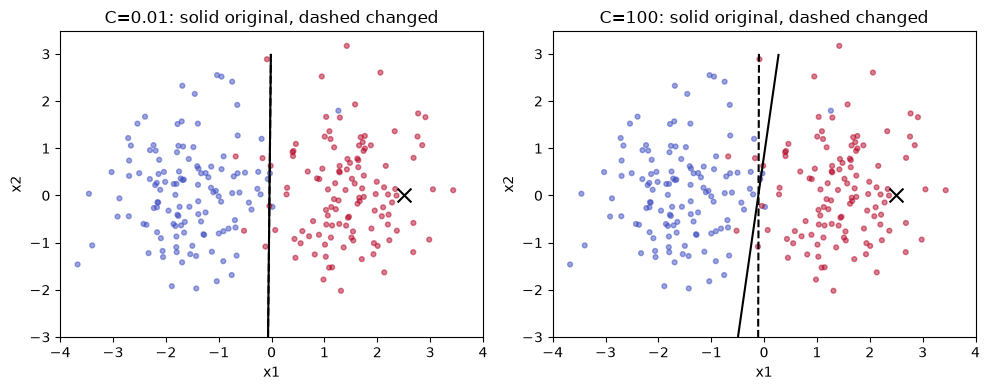

,C,original support,changed support,original mean slack,changed mean slack,mean absolute validation score change
0,0.01,156,158,0.258148,0.267404,0.000487
1,100.00,22,29,0.086322,0.112602,1.131563


In [5]:
extra_point = np.array([[2.5, 0.0]])
Z_augmented = np.vstack([Z_train, scaler.transform(extra_point)])
y_augmented = np.r_[y_train, -1]
Z_valid = scaler.transform(X_valid)
xx, yy = np.meshgrid(np.linspace(-4, 4, 160), np.linspace(-3, 3, 120))
grid = np.column_stack([xx.ravel(), yy.ravel()])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
perturbation_rows = []
for ax, C in zip(axes, [0.01, 100]):
    original = SVC(kernel="linear", C=C, tol=1e-6).fit(Z_train, y_train)
    changed = SVC(kernel="linear", C=C, tol=1e-6).fit(Z_augmented, y_augmented)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=12, alpha=0.5)
    for model, style in [(original, "-"), (changed, "--")]:
        scores = model.decision_function(scaler.transform(grid)).reshape(xx.shape)
        ax.contour(xx, yy, scores, levels=[0], colors="black", linestyles=style)
    ax.scatter(2.5, 0, marker="x", s=100, color="black")
    ax.set(title=f"C={C}: solid original, dashed changed", xlabel="x1", ylabel="x2")
    perturbation_rows.append({"C": C, "original support": len(original.support_),
        "changed support": len(changed.support_),
        "original mean slack": np.maximum(0, 1-y_train*original.decision_function(Z_train)).mean(),
        "changed mean slack": np.maximum(0, 1-y_augmented*changed.decision_function(Z_augmented)).mean(),
        "mean absolute validation score change": np.abs(changed.decision_function(Z_valid)
                                                          - original.decision_function(Z_valid)).mean()})
plt.tight_layout(); plt.show()
display(pd.DataFrame(perturbation_rows))

## 6. Audit validation and evaluate test

Use the original CV-selected model; compare test predictions with the training-majority baseline.
Accuracy is the correct fraction; ROC AUC measures score ranking, counting ties as half.
`confusion_matrix(labels=[-1,1])` puts actual labels in rows and predictions in columns;
`n_support_` counts supports by class. Margin quantiles are functional margins, not original-unit distances.

**Explain:** How can zero error coexist with positive hinge loss? Why is score 2 not 200% probability?
Did the conflicting row affect both C settings equally?

In [6]:
validation_score = selected.decision_function(X_valid)
print("Validation balanced accuracy:", balanced_accuracy_score(y_valid, np.where(validation_score >= 0, 1, -1)))
test_score = selected.decision_function(X_test)
prediction = np.where(test_score >= 0, 1, -1)
classes, counts = np.unique(y_train, return_counts=True)
majority = classes[counts.argmax()]
rows = []
for name, pred, score in [("Majority baseline", np.full(len(y_test), majority), np.zeros(len(y_test))),
                          ("Selected linear SVM", prediction, test_score)]:
    rows.append({"model": name, "accuracy": accuracy_score(y_test, pred),
                 "balanced accuracy": balanced_accuracy_score(y_test, pred),
                 "ROC AUC": roc_auc_score(y_test == 1, score)})
test_results = pd.DataFrame(rows).set_index("model")
display(test_results)
display(pd.DataFrame(confusion_matrix(y_test, prediction, labels=[-1, 1]),
                     index=["Actual -1", "Actual +1"], columns=["Predicted -1", "Predicted +1"]))
print("Support vectors by class:", selected.named_steps["svc"].n_support_)
print("Test functional-margin quantiles:", np.quantile(y_test * test_score, [0, 0.25, 0.5, 0.75, 1]))

Validation balanced accuracy: 0.9875


,accuracy,balanced accuracy,ROC AUC
model,,,
Majority baseline,0.5000,0.5000,0.5
Selected linear SVM,0.9875,0.9875,1.0


,Predicted -1,Predicted +1
Actual -1,40,0
Actual +1,1,39


Support vectors by class: [17 16]
Test functional-margin quantiles: [-0.57723295  1.94584658  2.69409019  3.57098473  5.90355626]


**Documentation reference:** [scikit-learn 1.8 SVM guide](https://scikit-learn.org/1.8/modules/svm.html).